In [1]:
# Установка библиотек для проекта

!pip install duckdb pandas numpy matplotlib seaborn scipy statsmodels

In [2]:
# Импорт библиотек

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

print("Game Analytics project started!")

Game Analytics project started!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving cookie_cats.csv.zip to cookie_cats.csv.zip


In [6]:
import zipfile

# Распаковываем архив
with zipfile.ZipFile("cookie_cats.csv.zip", "r") as zip_ref:
    zip_ref.extractall("data")

# Посмотрим, какие файлы внутри
import os

print(os.listdir("data"))

['cookie_cats.csv']


In [7]:
import pandas as pd

df = pd.read_csv("data/cookie_cats.csv")

print("Данные успешно загружены!")
print("Размер датасета:", df.shape)

display(df.head())

Данные успешно загружены!
Размер датасета: (90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [9]:
# Проверка качества данных

print("Количество пропусков:")
display(df.isnull().sum())

print("Количество полных дубликатов:")
print(df.duplicated().sum())

print("Количество уникальных игроков:")
print(df["userid"].nunique())

print("Количество повторяющихся ID:")
print(df["userid"].duplicated().sum())

Количество пропусков:


,0
userid,0
version,0
sum_gamerounds,0
retention_1,0
retention_7,0


Количество полных дубликатов:
0
Количество уникальных игроков:
90189
Количество повторяющихся ID:
0


In [10]:
group_analysis = df.groupby("version").agg(
    players=("userid", "nunique"),
    avg_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
    retention_d1=("retention_1", "mean"),
    retention_d7=("retention_7", "mean")
).reset_index()

group_analysis["retention_d1"] *= 100
group_analysis["retention_d7"] *= 100

display(group_analysis.round(2))

,version,players,avg_rounds,median_rounds,retention_d1,retention_d7
0,gate_30,44700,52.460,17.000,44.820,19.020
1,gate_40,45489,51.300,16.000,44.230,18.200


In [11]:
display(
    df["sum_gamerounds"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
    )
)

,sum_gamerounds
count,90189.000
mean,51.872
std,195.051
min,0.000
25%,5.000
50%,16.000
75%,51.000
90%,134.000
95%,221.000
99%,493.000


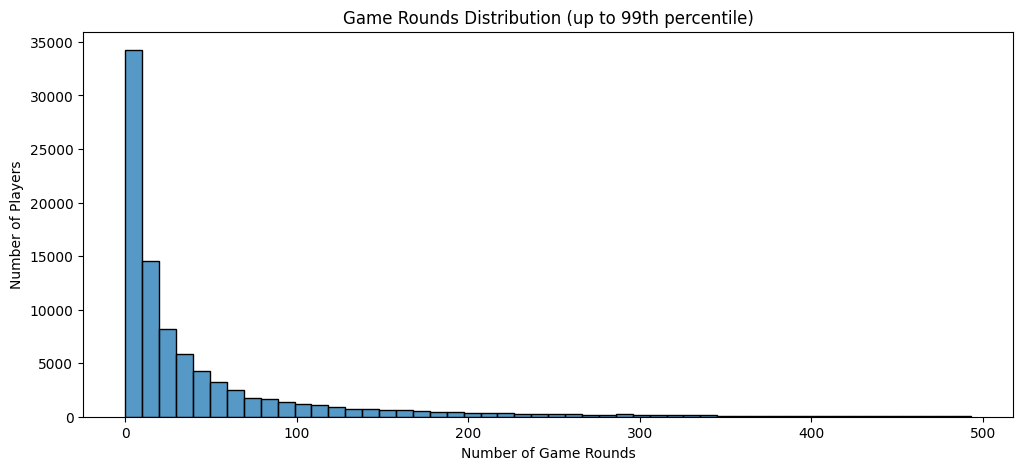

In [13]:
p99 = df["sum_gamerounds"].quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    df[df["sum_gamerounds"] <= p99]["sum_gamerounds"],
    bins=50
)

plt.title("Game Rounds Distribution (up to 99th percentile)")
plt.xlabel("Number of Game Rounds")
plt.ylabel("Number of Players")

plt.show()

In [14]:
from statsmodels.stats.proportion import proportions_ztest

# Разделяем игроков по группам
control = df[df["version"] == "gate_30"]
test = df[df["version"] == "gate_40"]

# Количество игроков, вернувшихся в игру
successes = [
    control["retention_1"].sum(),
    test["retention_1"].sum()
]

# Размеры групп
nobs = [
    len(control),
    len(test)
]

# Z-test для D1
z_stat, p_value = proportions_ztest(
    successes,
    nobs
)

print("Retention D1")
print("Z-statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 6))

Retention D1
Z-statistic: 1.7841
P-value: 0.07441


In [15]:
successes_d7 = [
    control["retention_7"].sum(),
    test["retention_7"].sum()
]

z_stat_d7, p_value_d7 = proportions_ztest(
    successes_d7,
    nobs
)

print("Retention D7")
print("Z-statistic:", round(z_stat_d7, 4))
print("P-value:", round(p_value_d7, 6))

Retention D7
Z-statistic: 3.1644
P-value: 0.001554


In [16]:
zero_players = df[df["sum_gamerounds"] == 0]

print("Игроков с нулём раундов:", len(zero_players))
print(
    "Доля игроков с нулём раундов:",
    round(len(zero_players) / len(df) * 100, 2),
    "%"
)

display(
    zero_players.groupby("version").agg(
        players=("userid", "count"),
        retention_d1=("retention_1", "mean"),
        retention_d7=("retention_7", "mean")
    )
)

Игроков с нулём раундов: 3994
Доля игроков с нулём раундов: 4.43 %


,players,retention_d1,retention_d7
version,,,
gate_30,1937,0.021,0.008
gate_40,2057,0.022,0.006


In [17]:
from statsmodels.stats.proportion import (
    proportion_confint,
    confint_proportions_2indep
)

metrics = ["retention_1", "retention_7"]

for metric in metrics:

    control_success = control[metric].sum()
    test_success = test[metric].sum()

    n_control = len(control)
    n_test = len(test)

    rate_control = control_success / n_control
    rate_test = test_success / n_test

    # Абсолютная разница
    diff = rate_control - rate_test

    # Относительный эффект
    relative_lift = diff / rate_test * 100

    # Доверительный интервал разницы
    ci_low, ci_high = confint_proportions_2indep(
        control_success,
        n_control,
        test_success,
        n_test,
        method="newcomb"
    )

    print(f"\n{metric.upper()}")
    print(f"Control: {rate_control:.4%}")
    print(f"Test: {rate_test:.4%}")
    print(f"Absolute difference: {diff:.4%}")
    print(f"Relative lift: {relative_lift:.2f}%")
    print(f"95% CI: [{ci_low:.4%}; {ci_high:.4%}]")


RETENTION_1
Control: 44.8188%
Test: 44.2283%
Absolute difference: 0.5905%
Relative lift: 1.34%
95% CI: [-0.0582%; 1.2392%]

RETENTION_7
Control: 19.0201%
Test: 18.2000%
Absolute difference: 0.8201%
Relative lift: 4.51%
95% CI: [0.3121%; 1.3282%]


In [18]:
import numpy as np

bins = [-1, 5, 15, 50, 150, np.inf]

labels = [
    "1. Very Low",
    "2. Low",
    "3. Medium",
    "4. High",
    "5. Very High"
]

df["activity_segment"] = pd.cut(
    df["sum_gamerounds"],
    bins=bins,
    labels=labels
)

segment_analysis = df.groupby(
    "activity_segment",
    observed=False
).agg(
    players=("userid", "nunique"),
    avg_rounds=("sum_gamerounds", "mean"),
    retention_d1=("retention_1", "mean"),
    retention_d7=("retention_7", "mean")
).reset_index()

segment_analysis["player_share"] = (
    segment_analysis["players"] / len(df) * 100
)

segment_analysis["retention_d1"] *= 100
segment_analysis["retention_d7"] *= 100

display(segment_analysis.round(2))

,activity_segment,players,avg_rounds,retention_d1,retention_d7,player_share
0,1. Very Low,24717,2.270,6.820,1.270,27.410
1,2. Low,19055,9.880,26.490,3.860,21.130
2,3. Medium,23605,29.200,58.840,13.500,26.170
3,4. High,14985,86.870,82.180,42.110,16.620
4,5. Very High,7827,312.120,92.170,79.670,8.680


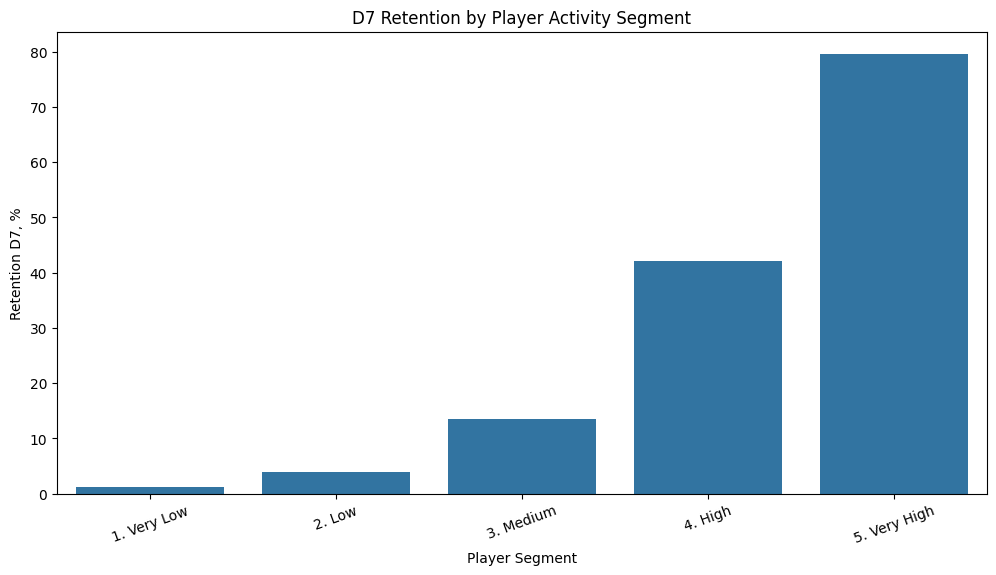

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_analysis,
    x="activity_segment",
    y="retention_d7"
)

plt.title("D7 Retention by Player Activity Segment")
plt.xlabel("Player Segment")
plt.ylabel("Retention D7, %")
plt.xticks(rotation=20)

plt.show()

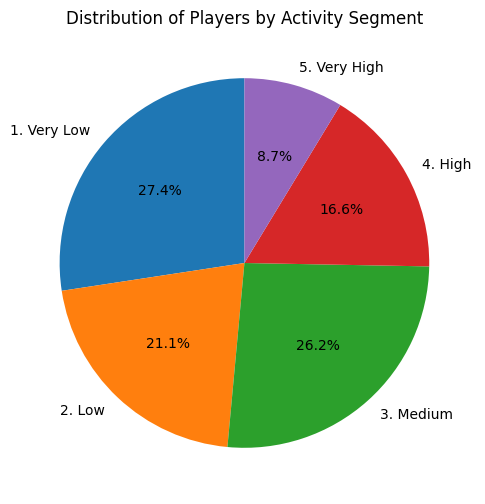

In [21]:
plt.figure(figsize=(12, 6))

plt.pie(
    segment_analysis["players"],
    labels=segment_analysis["activity_segment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Players by Activity Segment")
plt.show()

In [27]:

# ============================================================
# 7. SQL ANALYSIS
# ============================================================

con = duckdb.connect(":memory:")
con.register("players", df)

# QUERY 1. A/B TEST ANALYSIS

query_1 = """
SELECT
    version,
    COUNT(DISTINCT userid) AS players,
    ROUND(AVG(sum_gamerounds), 2) AS avg_rounds,

    ROUND(AVG(CAST(retention_1 AS INTEGER)) * 100, 2)
        AS retention_d1,

    ROUND(AVG(CAST(retention_7 AS INTEGER)) * 100, 2)
        AS retention_d7

FROM players
GROUP BY version
ORDER BY version;
"""

print("QUERY 1: A/B TEST ANALYSIS")
result_1 = con.execute(query_1).df()
display(result_1)


# QUERY 2. PLAYER SEGMENTATION

query_2 = """
WITH player_segments AS (
    SELECT
        userid,
        sum_gamerounds,
        retention_1,
        retention_7,

        CASE
            WHEN sum_gamerounds <= 5 THEN 'Very Low'
            WHEN sum_gamerounds <= 15 THEN 'Low'
            WHEN sum_gamerounds <= 50 THEN 'Medium'
            WHEN sum_gamerounds <= 150 THEN 'High'
            ELSE 'Very High'
        END AS activity_segment

    FROM players
)

SELECT
    activity_segment,
    COUNT(DISTINCT userid) AS players,
    ROUND(AVG(sum_gamerounds), 2) AS avg_rounds,

    ROUND(AVG(CAST(retention_1 AS INTEGER)) * 100, 2)
        AS retention_d1,

    ROUND(AVG(CAST(retention_7 AS INTEGER)) * 100, 2)
        AS retention_d7,

    ROUND(COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM players), 2) AS player_share

FROM player_segments

GROUP BY activity_segment

ORDER BY
    CASE activity_segment
        WHEN 'Very Low' THEN 1
        WHEN 'Low' THEN 2
        WHEN 'Medium' THEN 3
        WHEN 'High' THEN 4
        WHEN 'Very High' THEN 5
    END;
"""

print("\nQUERY 2: PLAYER SEGMENTATION")
result_2 = con.execute(query_2).df()
display(result_2)


QUERY 1: A/B TEST ANALYSIS


,version,players,avg_rounds,retention_d1,retention_d7
0,gate_30,44700,52.460,44.820,19.020
1,gate_40,45489,51.300,44.230,18.200



QUERY 2: PLAYER SEGMENTATION


,activity_segment,players,avg_rounds,retention_d1,retention_d7,player_share
0,Very Low,24717,2.270,6.820,1.270,27.410
1,Low,19055,9.880,26.490,3.860,21.130
2,Medium,23605,29.200,58.840,13.500,26.170
3,High,14985,86.870,82.180,42.110,16.620
4,Very High,7827,312.120,92.170,79.670,8.680


In [28]:

query_3 = """
WITH player_segments AS (

    SELECT
        userid,
        retention_7,

        CASE
            WHEN sum_gamerounds <= 5 THEN 'Very Low'
            WHEN sum_gamerounds <= 15 THEN 'Low'
            WHEN sum_gamerounds <= 50 THEN 'Medium'
            WHEN sum_gamerounds <= 150 THEN 'High'
            ELSE 'Very High'
        END AS activity_segment

    FROM players
),

segment_metrics AS (

    SELECT
        activity_segment,
        COUNT(DISTINCT userid) AS players,

        AVG(CAST(retention_7 AS INTEGER)) * 100
            AS retention_d7

    FROM player_segments
    GROUP BY activity_segment
),

ranked_segments AS (

    SELECT
        activity_segment,
        players,

        ROUND(retention_d7, 2) AS retention_d7,

        RANK() OVER (
            ORDER BY retention_d7 DESC
        ) AS retention_rank,

        ROUND(
            retention_d7 - LAG(retention_d7) OVER (
                ORDER BY
                    CASE activity_segment
                        WHEN 'Very Low' THEN 1
                        WHEN 'Low' THEN 2
                        WHEN 'Medium' THEN 3
                        WHEN 'High' THEN 4
                        WHEN 'Very High' THEN 5
                    END
            ), 2
        ) AS retention_change_pp

    FROM segment_metrics
)

SELECT *
FROM ranked_segments
ORDER BY retention_rank;
"""

print("QUERY 3: WINDOW FUNCTIONS")
result_3 = con.execute(query_3).df()
display(result_3)


QUERY 3: WINDOW FUNCTIONS


,activity_segment,players,retention_d7,retention_rank,retention_change_pp
0,Very High,7827,79.670,1,37.560
1,High,14985,42.110,2,28.610
2,Medium,23605,13.500,3,9.630
3,Low,19055,3.860,4,2.600
4,Very Low,24717,1.270,5,NaN



# 8. FINAL CONCLUSIONS & PRODUCT RECOMMENDATIONS

## Project Overview

The goal of this analysis was to evaluate the impact of moving the gate from level 30 to level 40 in Cookie Cats and identify patterns in player engagement and retention.

The analysis included:
- Exploratory Data Analysis (EDA)
- Data quality checks
- A/B test evaluation
- Statistical significance testing
- Confidence interval estimation
- Player segmentation
- SQL analysis using CTEs and window functions

## 1. A/B Test Results

The control group (gate_30) demonstrated better results across the analyzed metrics:

| Metric | gate_30 | gate_40 | Difference |
|---|---:|---:|---:|
| Average rounds | 52.46 | 51.30 | +1.16 |
| Retention D1 | 44.82% | 44.23% | +0.59 pp |
| Retention D7 | 19.02% | 18.20% | +0.82 pp |

Statistical testing showed:
- D1 retention difference was not statistically significant (p = 0.0744).
- D7 retention difference was statistically significant (p = 0.0016).
- The D7 result remained significant after Bonferroni correction for multiple comparisons.

**Conclusion:** The gate_30 variant demonstrated a statistically significant advantage in D7 retention. The available evidence does not support moving the gate from level 30 to level 40 if the primary objective is player retention.

## 2. Player Segmentation

Players were divided into five activity segments based on their total number of game rounds.

Key findings:
- 48.54% of players belonged to the Very Low and Low activity segments.
- The Very Low segment was the largest, representing 27.41% of all players.
- D7 retention increased from 1.27% in the Very Low segment to 79.67% in the Very High segment.

**Conclusion:** Player activity and retention are strongly associated in the observed data. The largest opportunity for further investigation is understanding the behavior of players with low activity.

Note: Segmentation is descriptive and uses total rounds over the observation period. It cannot be interpreted as an early churn prediction.

## 3. Product Recommendations

1. **Keep gate_30 as the preferred variant for retention.** The experiment results show a statistically significant advantage in D7 retention compared with gate_40.

2. **Investigate early player engagement.** The large share of players with low activity suggests an opportunity to study onboarding, first-session experience, and early progression.

3. **Run a follow-up experiment.** Analyze player progression through the first levels and test whether changes to early-game difficulty or onboarding improve retention.

4. **Add business metrics before making a final product decision.** Revenue, in-app purchases, level progression, and monetization data are needed to evaluate the overall business impact of the gate change.

## 4. Limitations

- The dataset does not contain timestamps or detailed event logs.
- Revenue and monetization metrics are not available.
- Player segmentation is based on total activity during the observation period.
- The analysis cannot identify the exact reasons behind differences in retention.

## Final Takeaway

The analysis indicates that keeping the gate at level 30 is preferable when optimizing for D7 retention. At the same time, the high share of low-activity players highlights the importance of investigating early engagement and onboarding.

Further product decisions should be supported by progression and monetization data.



# 8. ИТОГОВЫЕ ВЫВОДЫ И ПРОДУКТОВЫЕ РЕКОМЕНДАЦИИ

## О проекте

Цель исследования — оценить влияние переноса игрового ограничения (gate) с 30-го на 40-й уровень в игре Cookie Cats, а также выявить закономерности в активности и удержании игроков.

В рамках анализа были выполнены:
- Разведочный анализ данных (EDA).
- Проверка качества данных.
- Оценка результатов A/B-теста.
- Проверка статистической значимости различий.
- Расчёт доверительных интервалов.
- Сегментация игроков по активности.
- SQL-анализ с использованием CTE и оконных функций.

## 1. Результаты A/B-теста

Контрольная группа (gate_30) показала лучшие результаты по всем рассмотренным метрикам:

| Метрика | gate_30 | gate_40 | Разница |
|---|---:|---:|---:|
| Среднее количество раундов | 52,46 | 51,30 | +1,16 |
| Retention D1 | 44,82% | 44,23% | +0,59 п. п. |
| Retention D7 | 19,02% | 18,20% | +0,82 п. п. |

Результаты статистических тестов:
- Разница в Retention D1 статистически незначима (p = 0,0744).
- Разница в Retention D7 статистически значима (p = 0,0016).
- Результат по D7 сохранил статистическую значимость после поправки Бонферрони на множественные сравнения.

**Вывод:** Вариант gate_30 показал статистически значимое преимущество по удержанию игроков на седьмой день. Если основная цель — повышение Retention D7, имеющиеся результаты не подтверждают целесообразность переноса ограничения с 30-го на 40-й уровень.

## 2. Сегментация игроков

Игроки были разделены на пять сегментов в зависимости от общего количества пройденных игровых раундов.

Основные результаты:
- 48,54% игроков относятся к сегментам Very Low и Low.
- Самый многочисленный сегмент — Very Low, на него приходится 27,41% игроков.
- Retention D7 увеличивается с 1,27% в сегменте Very Low до 79,67% в сегменте Very High.

**Вывод:** В данных наблюдается выраженная связь между игровой активностью и удержанием. Отдельного внимания заслуживает поведение игроков с низкой активностью, поскольку они составляют значительную долю аудитории.

Важно: сегментация основана на общем количестве раундов за период наблюдения. Она носит описательный характер и не позволяет прогнозировать ранний отток игроков.

## 3. Продуктовые рекомендации

1. **Сохранить gate_30 как предпочтительный вариант с точки зрения удержания.** Результаты эксперимента показывают статистически значимое преимущество этого варианта по Retention D7.

2. **Исследовать вовлечённость новых игроков.** Значительная доля пользователей с низкой активностью указывает на необходимость изучить процесс знакомства с игрой, первый игровой сеанс и прохождение начальных уровней.

3. **Провести дополнительный эксперимент.** Изучить прогресс игроков на первых уровнях и проверить, могут ли изменения сложности или обучения улучшить удержание.

4. **Дополнить анализ бизнес-метриками.** Для оценки общего эффекта изменения игрового механизма необходимы данные о выручке, внутриигровых покупках, прогрессе по уровням и монетизации.

## 4. Ограничения исследования

- В датасете отсутствуют временные метки и подробные логи игровых событий.
- Нет данных о выручке и монетизации.
- Сегментация основана на общей активности за период наблюдения.
- Исследование не позволяет определить точные причины различий в удержании.

## Итог

Результаты анализа показывают, что с точки зрения Retention D7 предпочтительнее сохранить ограничение на 30-м уровне. При этом высокая доля игроков с низкой активностью указывает на необходимость дополнительного исследования первых игровых сессий и процесса вовлечения пользователей.

Для принятия окончательного продуктового решения исследование следует дополнить данными о прогрессе игроков и монетизации.
